<a href="https://colab.research.google.com/github/paulchilemya2024-beep/DATA-SCIENCE-CS250-/blob/main/Ch7_Regression_Assignment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ANSWER KEY: In-Class Assignment: Predicting New Orleans Home Prices with Regression
**Introduction to Data Science with Python, Chapter 7: Regression**

## Scenario
A local real estate company wants a tool that estimates a home's sale price. You have data on **150 homes** in the New Orleans area. Your job is to build regression models, interpret them, and decide which model the company should use.

| Column | Description |
|---|---|
| `sqft` | Living area in square feet |
| `bedrooms` | Number of bedrooms |
| `bathrooms` | Number of bathrooms |
| `age_years` | Age of the home in years |
| `miles_to_downtown` | Distance to downtown New Orleans |
| `price` | Sale price in dollars (**the target we want to predict**) |

## What you'll practice
1. Exploring relationships with correlation and scatter plots
2. Fitting a simple linear regression model
3. Interpreting the slope, intercept, and R²
4. Making predictions and checking residuals
5. Evaluating a model on a test set
6. Building and interpreting a multiple regression model

## Instructions
- Work through each part in order.
- Use the ✅ **Checkpoints** to confirm your answers before moving on.
- Answer the questions in the text cells. Some questions ask you to *explain*, not just calculate.



## Setup
Run both cells below. The first imports the libraries you need. The second lets you upload the dataset to Colab.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [ ]:
# Run this cell, click "Choose Files," and select nola_home_prices.csv
from google.colab import files
uploaded = files.upload()

Saving nola_home_prices.csv to nola_home_prices.csv


## Part 1: Explore the Data
Before building a model, look at the data and check which features are related to price.

**Your tasks:**
1. Load **nola_home_prices.csv** into a DataFrame named `df` and display the first five rows.
2. Use `describe()` to summarize each column.
3. Calculate the correlation between each feature and `price`, sorted from highest to lowest. (Drop the `home_id` column first.)
4. Create a scatter plot with `sqft` on the x-axis and `price` on the y-axis. Label both axes and add a title.

💡 **Hint:** `df.drop(columns="home_id").corr()["price"].sort_values(ascending=False)`

✅ **Checkpoint:** The dataset has **150 rows and 7 columns**, and `sqft` has the strongest correlation with price (**r = 0.89**).

In [ ]:
df = pd.read_csv("nola_home_prices.csv")
print(df.shape)
df.head()

(150, 7)


,home_id,sqft,bedrooms,bathrooms,age_years,miles_to_downtown,price
0,1,1340,2,1.5,36,14.5,181100
1,2,1880,3,1.5,18,10.0,281200
2,3,760,1,1.5,90,10.9,56300
3,4,2480,3,3.5,24,12.9,303900
4,5,2080,4,2.5,36,8.7,288100


In [ ]:
df.describe().round(1)

,home_id,sqft,bedrooms,bathrooms,age_years,miles_to_downtown,price
count,150.0,150.0,150.0,150.0,150.0,150.0,150.0
mean,75.5,1788.2,3.0,2.0,46.8,8.4,236444.0
std,43.4,543.4,1.1,0.7,26.4,4.0,71008.7
min,1.0,750.0,1.0,1.0,5.0,1.1,55900.0
25%,38.2,1400.0,2.0,1.5,27.2,5.2,185225.0
50%,75.5,1760.0,3.0,2.0,42.5,9.0,234900.0
75%,112.8,2142.5,4.0,2.5,63.5,11.9,287625.0
max,150.0,3390.0,5.0,3.5,110.0,15.0,414900.0


In [ ]:
df.drop(columns="home_id").corr()["price"].sort_values(ascending=False).round(2)

,price
price,1.00
sqft,0.89
bedrooms,0.74
bathrooms,0.71
age_years,-0.25
miles_to_downtown,-0.28


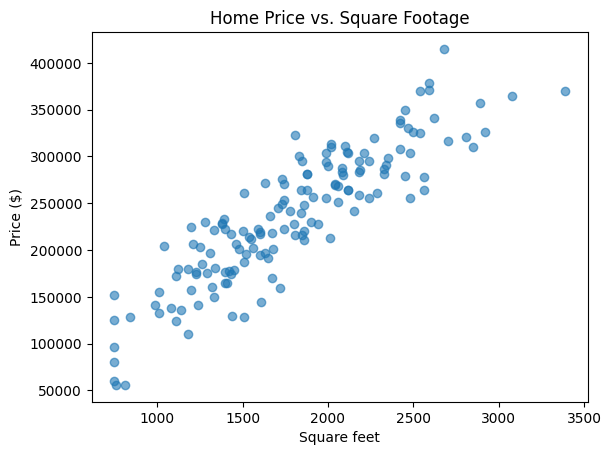

In [ ]:
plt.scatter(df["sqft"], df["price"], alpha=0.6)
plt.xlabel("Square feet")
plt.ylabel("Price ($)")
plt.title("Home Price vs. Square Footage")
plt.show()

**Question 1:** Which feature has the *weakest* relationship with price? Do the negative correlations for `age_years` and `miles_to_downtown` make sense? Explain.

* **Weakest Relationship:** `age_years` has the weakest relationship with price ($r = -0.25$).
* **Do they make sense?** Yes, both negative correlations are intuitive:
  * For `age_years` ($r = -0.25$), older homes typically require more maintenance, have outdated designs, or need renovations, which tends to lower their market value.
  * For `miles_to_downtown` ($r = -0.28$), homes located further from the city center are farther from major job centers, transit, and entertainment, leading to lower prices compared to the premium paid to live closer to downtown.

## Part 2: Simple Linear Regression
Build a model that predicts price using **only** square footage.

**Your tasks:**
1. Create `X` (a DataFrame with only the `sqft` column) and `y` (the `price` column).
2. Create a `LinearRegression()` model named `simple_model` and fit it.
3. Print the intercept, slope, and R².
4. Plot the data with the line of best fit drawn in red.

💡 **Hints:**
- Use double brackets for `X`: `df[["sqft"]]`. scikit-learn expects a table of features, even if there's only one.
- The intercept is `simple_model.intercept_`, and the slope is `simple_model.coef_[0]`.
- R² is `simple_model.score(X, y)`.

✅ **Checkpoint:** Slope ≈ **115.92**, intercept ≈ **29,164.30**, R² ≈ **0.787**

In [ ]:
X = df[["sqft"]]
y = df["price"]
simple_model = LinearRegression()
simple_model.fit(X, y)
print("Intercept:", round(simple_model.intercept_, 2))
print("Slope:", round(simple_model.coef_[0], 2))
print("R-squared:", round(simple_model.score(X, y), 3))

Intercept: 29164.3
Slope: 115.92
R-squared: 0.787


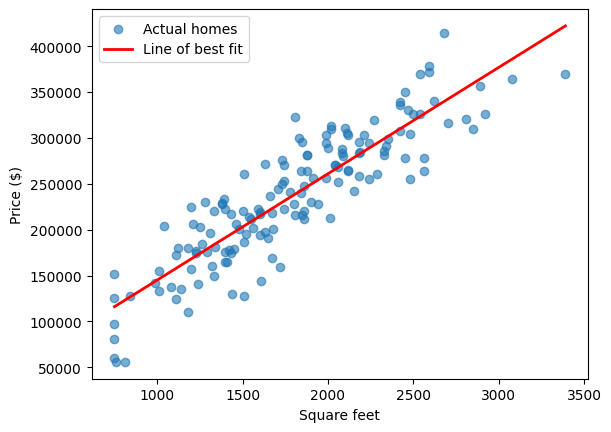

In [ ]:
x_line = pd.DataFrame({"sqft": np.linspace(df["sqft"].min(), df["sqft"].max(), 100)})
plt.scatter(df["sqft"], df["price"], alpha=0.6, label="Actual homes")
plt.plot(x_line["sqft"], simple_model.predict(x_line), color="red", linewidth=2, label="Line of best fit")
plt.xlabel("Square feet")
plt.ylabel("Price ($)")
plt.legend()
plt.show()

**Question 2:** Write the regression equation in the form *ŷ = b₀ + b₁x*. Then interpret the **slope** in one sentence a home buyer would understand.

* **Regression Equation:** $\hat{y} = 29,164.30 + 115.92x$
* **Slope Interpretation:** For every additional square foot of living space a home has, its predicted sale price increases by approximately **$115.92**.

**Question 3:** What does the R² value tell you about this model?

* The $R^2$ of **0.787** indicates that **78.7%** of the variation in New Orleans home prices can be explained by the square footage of the home alone.

## Part 3: Make a Prediction and Check the Residuals
**Your tasks:**
1. Use `simple_model` to predict the price of a **2,000 square foot** home.
2. Calculate the residuals (actual price − predicted price) and create a **residual plot**: predicted values on the x-axis, residuals on the y-axis, and a horizontal line at 0.

💡 **Hint:** Predictions need the same format as `X`: `pd.DataFrame({"sqft": [2000]})`. Use `plt.axhline(0)` for the zero line.

✅ **Checkpoint:** The predicted price is about **$260,995**.

In [ ]:
new_home = pd.DataFrame({"sqft": [2000]})
print("Predicted price:", round(simple_model.predict(new_home)[0], 2))

Predicted price: 260994.86


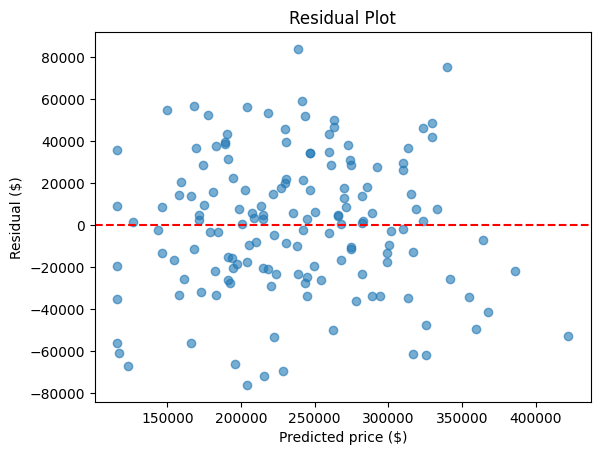

In [ ]:
fitted = simple_model.predict(X)
residuals = y - fitted
plt.scatter(fitted, residuals, alpha=0.6)
plt.axhline(0, color="red", linestyle="--")
plt.xlabel("Predicted price ($)")
plt.ylabel("Residual ($)")
plt.title("Residual Plot")
plt.show()

**Question 4:** Look at your residual plot. Are the points scattered randomly around 0, or do you see a pattern? What does that tell you about whether a straight line is a good fit?

* The points on the residual plot are scattered randomly around the horizontal line at 0 with no distinct curved shape or funnel pattern. This indicates that a straight line is indeed an appropriate and good fit for this relationship.

**Question 5:** Would you trust this model to predict the price of a **6,000 square foot** home? Why or why not?

* No, you should not trust the model for a 6,000 square foot home. This is a case of **extrapolation** because the largest home in our dataset is only 3,390 square feet. Linear patterns often change outside the range of observed data, especially for luxury/mansion-sized homes.

## Part 4: Evaluate the Model on New Data
So far, we've judged the model on the same data it learned from. To get an honest measure, split the data into training and test sets.

**Your tasks:**
1. Split `X` and `y` into training (80%) and test (20%) sets. Use `random_state=42`.
2. Refit `simple_model` on the **training** data only.
3. Predict on the **test** data and print the MAE, RMSE, and R².

💡 **Hint:** RMSE is `np.sqrt(mean_squared_error(y_test, y_pred))`

✅ **Checkpoint:** 120 training rows and 30 test rows. Test R² ≈ **0.641** and MAE ≈ **$30,003**

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(len(X_train), len(X_test))

120 30


In [ ]:
simple_model.fit(X_train, y_train)
y_pred = simple_model.predict(X_test)
print("MAE: ", round(mean_absolute_error(y_test, y_pred), 2))
print("RMSE:", round(np.sqrt(mean_squared_error(y_test, y_pred)), 2))
print("R²:  ", round(r2_score(y_test, y_pred), 3))

MAE:  30002.88
RMSE: 35366.56
R²:   0.641


## Part 5: Multiple Linear Regression
Square footage isn't the only thing that affects price. Build a model that uses **all five features**.

**Your tasks:**
1. Create `X_multi` with the columns `sqft`, `bedrooms`, `bathrooms`, `age_years`, and `miles_to_downtown`.
2. Split it into training and test sets (80/20, `random_state=42`).
3. Fit a `LinearRegression()` model named `multi_model` and print the test MAE, RMSE, and R².
4. Display the intercept and a table of each feature's coefficient.
5. Predict the price of this home: **2,000 sq ft, 3 bedrooms, 2 bathrooms, 30 years old, 5 miles from downtown**.

✅ **Checkpoint:** Test R² ≈ **0.851**, MAE ≈ **$18,956**, and the predicted price is about **$288,198**.

In [ ]:
features = ["sqft", "bedrooms", "bathrooms", "age_years", "miles_to_downtown"]
X_multi = df[features]
Xm_train, Xm_test, ym_train, ym_test = train_test_split(X_multi, y, test_size=0.2, random_state=42)
multi_model = LinearRegression()
multi_model.fit(Xm_train, ym_train)
ym_pred = multi_model.predict(Xm_test)
print("MAE: ", round(mean_absolute_error(ym_test, ym_pred), 2))
print("RMSE:", round(np.sqrt(mean_squared_error(ym_test, ym_pred)), 2))
print("R²:  ", round(r2_score(ym_test, ym_pred), 3))

MAE:  18956.42
RMSE: 22811.78
R²:   0.851


In [ ]:
coefficients = pd.DataFrame({"feature": features, "coefficient": multi_model.coef_.round(2)})
print("Intercept:", round(multi_model.intercept_, 2))
coefficients

Intercept: 99831.92


,feature,coefficient
0,sqft,110.40
1,bedrooms,2356.42
2,bathrooms,2728.89
3,age_years,-742.90
4,miles_to_downtown,-4535.78


In [ ]:
house = pd.DataFrame({"sqft": [2000], "bedrooms": [3], "bathrooms": [2],
                      "age_years": [30], "miles_to_downtown": [5]})
print("Predicted price:", round(multi_model.predict(house)[0], 2))

Predicted price: 288198.22


## Part 6: Compare the Models
Create a table comparing the simple and multiple regression models on MAE, RMSE, and R².

In [ ]:
comparison = pd.DataFrame({
    "Model": ["Simple (sqft only)", "Multiple (5 features)"],
    "MAE": [mean_absolute_error(y_test, y_pred), mean_absolute_error(ym_test, ym_pred)],
    "RMSE": [np.sqrt(mean_squared_error(y_test, y_pred)), np.sqrt(mean_squared_error(ym_test, ym_pred))],
    "R²": [r2_score(y_test, y_pred), r2_score(ym_test, ym_pred)]}).round(3)
comparison

,Model,MAE,RMSE,R²
0,Simple (sqft only),30002.879,35366.561,0.641
1,Multiple (5 features),18956.418,22811.778,0.851


**Question 6:** Interpret the coefficient for `age_years`. Remember: in multiple regression, each coefficient describes the effect of that feature **while holding the other features constant**.

* Holding all other features (square footage, bedrooms, bathrooms, and distance to downtown) constant, each additional year of a home's age is associated with an average decrease in price of **$742.90**.

**Question 7:** In Part 1, `bedrooms` had a strong correlation with price (0.74). Why is its coefficient so much smaller than you might expect in the multiple regression model? (Hint: think about how bedrooms and square footage are related.)

* This is due to **multicollinearity**. Square footage and the number of bedrooms are strongly correlated because larger homes naturally have more bedrooms. Since square footage is already accounting for the size of the home in the model, the `bedrooms` coefficient only represents the minor incremental value of partitioning that existing space into more rooms.

**Question 8:** Which model should the real estate company use? Support your answer with at least two numbers from your comparison table.

* The company should use the **Multiple Regression Model** because it is significantly more accurate and explains more variance:
  * It has a much higher test $R^2$ of **0.851** compared to **0.641** for the simple model (explaining 85.1% of the pricing variance instead of 64.1%).
  * It dramatically reduces the prediction error, bringing the Mean Absolute Error (MAE) down to **$18,956.42** from the simple model's **$30,002.88** (an improvement of over $11,000 per prediction).

## 🌟 Challenge (Optional)
Would a curved line fit better than a straight one? Use `PolynomialFeatures(degree=2)` to build a polynomial regression model on `sqft` and compare its test R² to the simple linear model. Is the extra complexity worth it?

In [ ]:
from sklearn.preprocessing import PolynomialFeatures
poly = PolynomialFeatures(degree=2, include_bias=False)
Xp_train = poly.fit_transform(X_train)
Xp_test = poly.transform(X_test)
poly_model = LinearRegression().fit(Xp_train, y_train)
print("Polynomial R²:", round(r2_score(y_test, poly_model.predict(Xp_test)), 3))

Polynomial R²: 0.63
